# Gradient Descent

## Loading Dataset

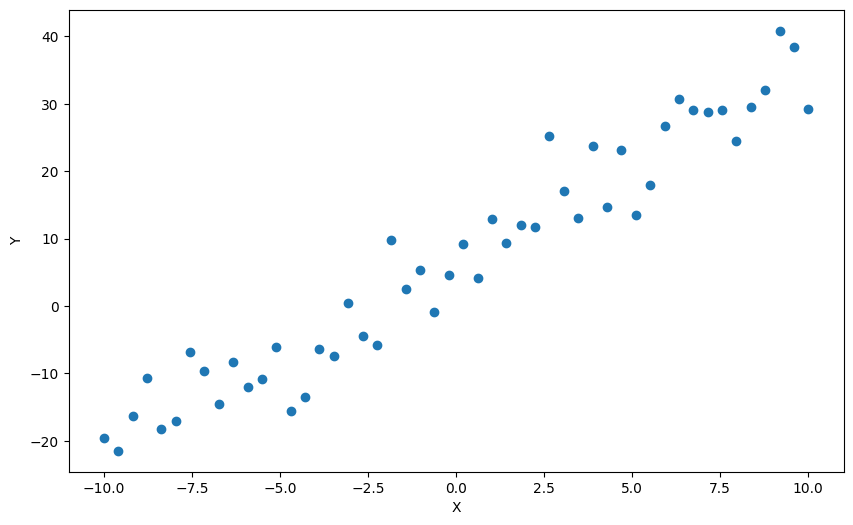

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_data(n_samples=50, noise=5.0):
    np.random.seed(42)
    X = np.linspace(-10, 10, n_samples)
    # Ground truth line: y = 3x + 8
    true_slope = 3
    true_intercept = 8
    noise = np.random.randn(n_samples) * noise
    y = true_slope * X + true_intercept + noise
    return X, y

X, y = generate_data(n_samples=50, noise=5.0)
m = len(y)
X_b = np.c_[np.ones((m, 1)), X]

plt.figure(figsize=(10, 6))
plt.scatter(X, y)
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

## Cost Function

The **cost function** measures how well our model's predictions match the actual data. For linear regression, we use **half the Mean Squared Error (MSE)**, defined as:

$$ J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2 $$

The factor $\frac{1}{2}$ makes the derivative simpler. Our goal in gradient descent is to find the values of $\theta$ that minimize this function. The code below implements this formula.

In [2]:
def compute_cost(X_b, y, theta):
    # X_b (ndarray): The input features with a column of ones. Shape (m, n+1).
    # y (ndarray): The target values. Shape (m,).
    # theta (ndarray): The parameters of the model. Shape (n+1,).
    m = len(y)
    predictions = X_b @ theta
    cost = (1 / (2 * m)) * np.sum((predictions -y ) ** 2)
    return cost

## Gradient Descent Algorithm

Assuming we need to find $ \theta_0\ and\ \theta_1 $ in the problem of linear regression, update rule using gradinet descent will be:

$$ \theta_j := \theta_j - \alpha \frac{\partial J}{\partial \theta_j} $$

$$ \theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)} $$

we'll calculate the gradients for all $\theta_j$ at once and update `theta` simultaneously. 

Here $ \alpha $ is the learning rate.

In [3]:
def gradient_descent(X_b, y, theta, alpha, iterations):
    # X_b (ndarray): Input features with a column of ones.
    # y (ndarray): Target values.
    # theta (ndarray): Initial parameters.
    # alpha (float): The learning rate.
    # iterations (int): The number of iterations to run.

    m = len(y)
    cost_history = [compute_cost(X_b, y, theta)]
    theta_history = [theta.copy()]

    for i in range(iterations):
        predictions = X_b @ theta
        errors = predictions - y
        gradients = (X_b.T @ errors) / m
        theta = theta - alpha * gradients

        cost_history.append(compute_cost(X_b, y, theta))
        theta_history.append(theta.copy())

    return theta, cost_history, theta_history

## Choose Hyperparameters and Run Gradient Descent

In [4]:
# Setup
iterations = 100
# Start with theta_0 = 0 and theta_1 = 0
initial_theta = np.zeros(2) 

# learning rate
alpha = 0.05

# Run Gradient Descent
theta, cost_history, theta_history = gradient_descent(X_b, y, initial_theta, alpha, iterations)


print(f"Final theta for alpha={alpha}: {theta}")

Final theta for alpha=0.05: [6.83194086 2.8550415 ]


## Plot GD Progression

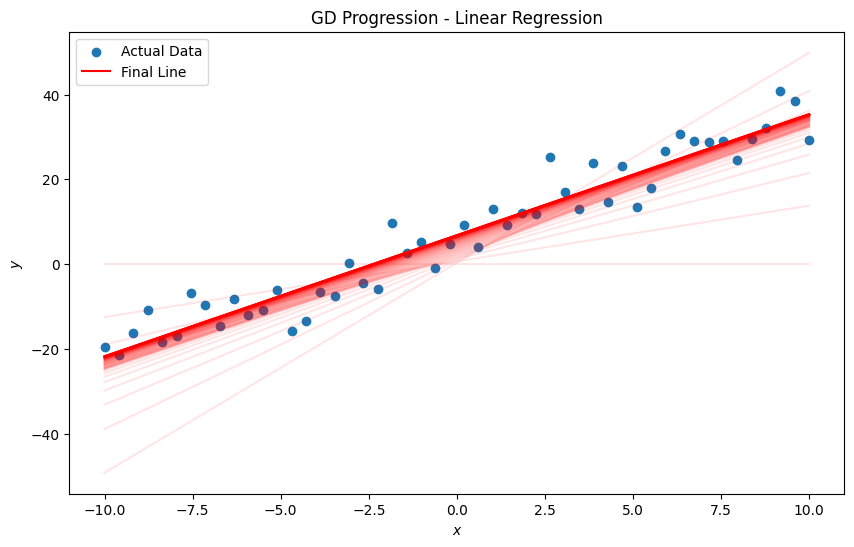

In [5]:
y_pred = X_b @ theta

plt.figure(figsize=(10, 6))
plt.scatter(X, y, label='Actual Data')

for theta in theta_history[:-1]:
    plt.plot(X, X_b @ theta, color='red', alpha=0.1)

plt.plot(X, y_pred, color='red', label='Final Line')
plt.title("GD Progression - Linear Regression")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()

## Plot cost function

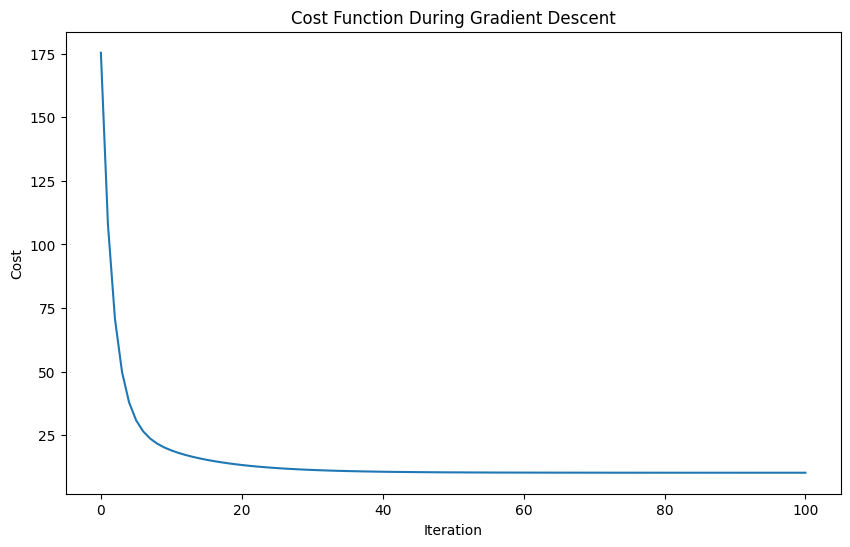

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(range(iterations + 1), cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost Function During Gradient Descent")
plt.show()

## Multivariable Example: Predicting House Prices

In the previous examples, we predicted $y$ using only **one input variable**. Now, let's predict the price of a house using **two input features**:

- $x_1$: House area (square meters)
- $x_2$: Number of bedrooms
- $y$: House price (in thousands of dollars)

Our hypothesis becomes:

$$h_\theta(x) = \theta_0 + \theta_1x_1 + \theta_2x_2$$

### Loading Dataset

X shape: (60, 2)
y shape: (60,)


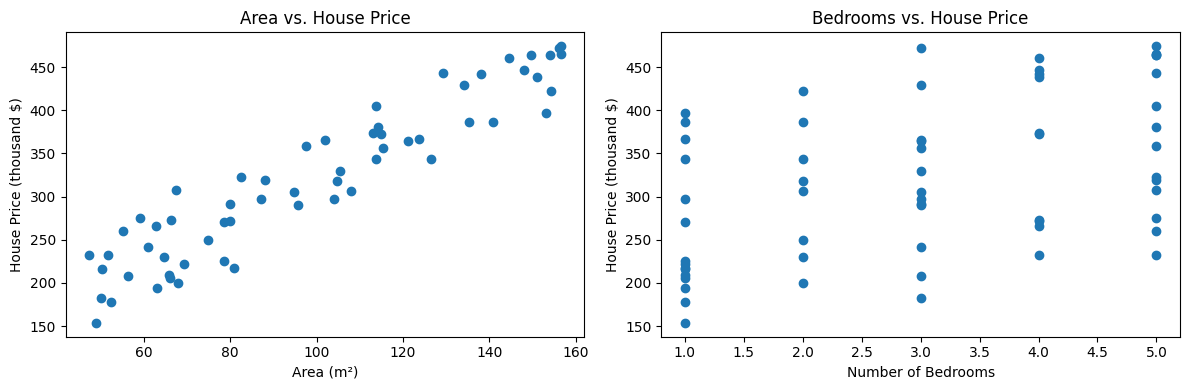

In [7]:
np.random.seed(42)

area = np.random.uniform(45, 160, size=60)              # Feature 1: area (m²)
bedrooms = np.random.randint(1, 6, size=60)          # Feature 2: bedrooms (1 to 5)

# Generate house prices (in thousands of dollars), including some noise
y = 40 + 2.3 * area + 18 * bedrooms + np.random.normal(0, 17, size=60)

# Each row represents one house, and each column represents one feature
X = np.c_[area, bedrooms]
m = len(y)

print("X shape:", X.shape)  # (60, 2)
print("y shape:", y.shape)  # (60,)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y)
plt.xlabel('Area (m²)')
plt.ylabel('House Price (thousand $)')
plt.title('Area vs. House Price')

plt.subplot(1, 2, 2)
plt.scatter(X[:, 1], y)
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Price (thousand $)')
plt.title('Bedrooms vs. House Price')

plt.tight_layout()
plt.show()

### Prepare the Features

The **area** values are much larger than the **bedroom** values. If we apply gradient descent directly, the same learning rate may be too large for one feature and too small for the other.

We'll standardize each feature using its own mean and standard deviation:

$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

Then, just as before, we'll add a **column of ones** to form $X_b$. We standardize only the input features, **not** the intercept column.

In [8]:
# Feature scaling (calculate statistics from the training data)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_scaled = (X - X_mean) / X_std

# Same design-matrix approach, now with THREE columns
X_b = np.c_[np.ones((m, 1)), X_scaled]

print("Design matrix shape:", X_b.shape)  # (60, 3)
print("First three rows:\n", X_b[:3])

Design matrix shape: (60, 3)
First three rows:
 [[ 1.         -0.30692813  1.33829921]
 [ 1.          1.59542587 -0.66914961]
 [ 1.          0.87327696  1.33829921]]


### Gradient Descent for Multiple Features

We use **the same cost function** as in the earlier examples:

$$J(\boldsymbol\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)})-y^{(i)}\right)^2$$

The update rule is also unchanged, but now it updates **three** parameters ($\theta_0$, $\theta_1$, and $\theta_2$):

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha\frac{1}{m}X_b^\top(X_b\boldsymbol\theta - \mathbf y)$$

Let's initialize all three parameters to zero, choose a learning rate, and run gradient descent.

In [9]:
# Setup 
iterations = 300
initial_theta = np.zeros(3)
alpha = 0.1

# Reuse the SAME gradient_descent function from the first example
theta, cost_history, theta_history = gradient_descent(
    X_b, y, initial_theta, alpha, iterations
)

print(f"Final theta for alpha={alpha}: {theta}")
print(f"Initial cost: {compute_cost(X_b, y, initial_theta):.2f}")
print(f"Final cost:   {cost_history[-1]:.2f}")

Final theta for alpha=0.1: [320.34868983  79.32863112  26.46548687]
Initial cost: 55327.42
Final cost:   126.22


### Plot Cost Function

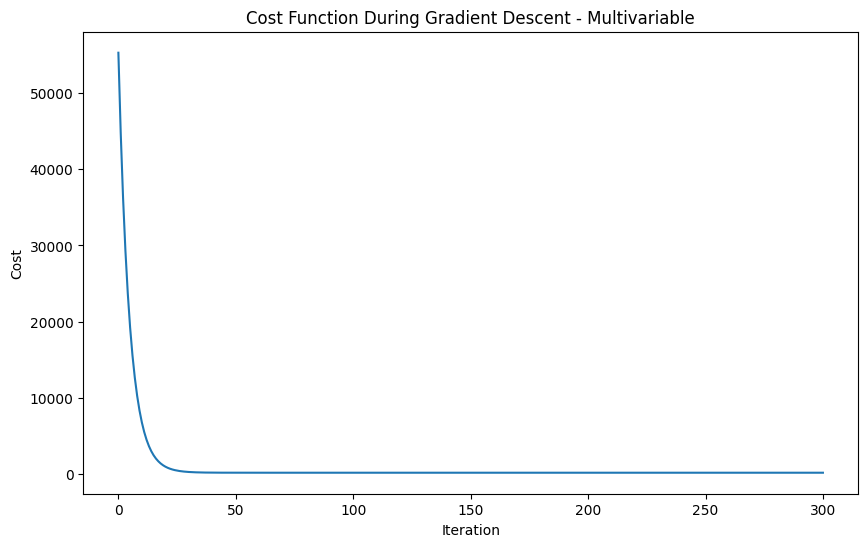

In [10]:
# Same cost-history plot as in the previous examples
plt.figure(figsize=(10, 6))
plt.plot(range(iterations + 1), cost_history)
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('Cost Function During Gradient Descent - Multivariable')
plt.show()

### Make a Prediction for a New House

Suppose we have a new house with an **area of 110 m²** and **3 bedrooms**. Before prediction, we must standardize its features with **the same means and standard deviations** used for the training data.

Our fitted parameters correspond to standardized features. To interpret them in the original units, we can also convert them back:

$$\theta_{j,\mathrm{original}} = \frac{\theta_{j,\mathrm{scaled}}}{\sigma_j} \quad (j=1,2)$$

$$\theta_{0,\mathrm{original}} = \theta_{0,\mathrm{scaled}} - \sum_{j=1}^{2}\theta_{j,\mathrm{original}}\mu_j$$

In [11]:
# A new observation: [area, number of bedrooms]
new_house = np.array([[110.0, 3.0]])
new_house_scaled = (new_house - X_mean) / X_std
new_house_b = np.c_[np.ones((len(new_house_scaled), 1)), new_house_scaled]

predicted_price = (new_house_b @ theta)[0]
print(f"Predicted house price: ${predicted_price * 1000:,.0f}")

# Convert coefficients back to original feature units for interpretation
slopes_original = theta[1:] / X_std
intercept_original = theta[0] - np.sum(slopes_original * X_mean)

print("\nModel in original units (price in thousands of dollars):")
print(f"Price = {intercept_original:.2f}"
      f" + {slopes_original[0]:.2f} * Area"
      f" + {slopes_original[1]:.2f} * Bedrooms")

Predicted house price: $345,943

Model in original units (price in thousands of dollars):
Price = 42.28 + 2.28 * Area + 17.71 * Bedrooms
